# 01 — Les datasets : du texte brut aux tenseurs d'indices

**Chapitre 2 · Du bigramme au mini-GPT** · durée conseillée : 20 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/chapitre_2/01_datasets.ipynb)

![Parcours du chapitre](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/fr/chapitre_2/figures/00_parcours.png)

Au chapitre 1, nous avons travaillé sur des **prénoms**. Nous passons maintenant à de **vrais textes** : un modèle de langage apprend la façon dont *un* texte est écrit. Changer de texte, c'est changer ce que le modèle va imiter.

**À la fin de ce notebook, vous saurez :**
1. charger et comparer trois corpus (Shakespeare, Kaamelott, Platon) ;
2. expliquer ce qu'est un **vocabulaire** de caractères et un **tokeniseur** ;
3. transformer un texte en tenseur d'indices `torch.long` ;
4. séparer **entraînement** et **validation**, et dire pourquoi la taille du corpus compte.

> **Idée clé :** un réseau de neurones ne lit pas de lettres. Il ne manipule que des nombres. Toute la chaîne commence donc par une table de correspondance *caractère ↔ entier*.

In [1]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme minigpt.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/chapitre_2

In [2]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

PyTorch 2.15.0+cu132 | périphérique : cuda


## 1. Trois corpus, trois « styles » à imiter

| Corpus | Fichier | Contenu |
|---|---|---|
| **Shakespeare** | `shakespeare.txt` | *Tiny Shakespeare* : extraits de pièces, ≈ 1 M de caractères. C'est le corpus de la vidéo de Karpathy. |
| **Kaamelott** | `kaamelott.txt` | Les 455 épisodes de la série (dataset Kaggle [*Kaamelott TV show transcripts*](https://www.kaggle.com/datasets/jeanmidev/kaamelott-tv-show-transcripts-fr)), une réplique par ligne au format `PERSONNAGE: réplique`, ≈ 2,4 M de caractères. |
| **Platon** | `plato_train.txt` | Dialogues de Platon dans la traduction de Victor Cousin (XIXᵉ s.), ≈ 4 M de caractères. |

Les textes sont utilisés **tels quels**. Seul Kaamelott a été mis en forme une fois pour toutes à partir du fichier CSV du dataset (script `preparer_kaamelott.py`, à côté des corpus) : une réplique par ligne, une ligne vide entre deux épisodes. Les lignes `=== PLA_... ===` de Platon (titres des dialogues) font partie du texte que le modèle apprendra.

La fonction `minigpt.charger_texte(nom)` cherche simplement le fichier à côté du notebook, puis dans le dossier `corpus/` du dépôt : c'est un `open(...).read()`.

In [3]:
textes = {nom: minigpt.charger_texte(nom) for nom in ["shakespeare", "kaamelott", "platon"]}

for nom, texte in textes.items():
    print(f"=== {nom} : {len(texte):,} caractères ===")
    print(texte[:300])
    print()

=== shakespeare : 1,115,394 caractères ===
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us

=== kaamelott : 2,429,148 caractères ===
KARADOC: Bon, je vais essayer de trouver un petit lièvre pour ce soir parce qu’il commence à faire faim !
BOHORT: Je me demande comment vous faîtes, moi je serais incapable de trouver de quoi manger dans la forêt.
KARADOC: Pour attraper des bêtes, il faut imiter les femelles. Là, pour le coup, hop !

=== platon : 3,892,898 caractères ===
=== PLA_Apologie_de_Socrate ===

MÉLITUS:
Non, sans doute.

SOCRATE:
Eh bien donc, dis à nos juges qui est-ce qui est capable de rendre les jeunes gens meilleurs ; car il ne faut pas douter que tu ne le saches, puisque cela t'occupe si fort. En effet, puisque tu as découver

### Lire les aperçus

- Les **retours à la ligne**, les **espaces** et la **ponctuation** sont des caractères comme les autres. Le modèle apprendra donc aussi la *mise en page* : noms de personnages, deux-points, sauts de ligne entre répliques.
- Shakespeare est en anglais (sans accents), Kaamelott et Platon en français (avec `é`, `è`, `ç`, `’`…).

**Question :** d'après vous, lequel des trois corpus aura le plus grand vocabulaire de caractères ? Lequel sera le plus difficile à apprendre ?

In [4]:
# Comparer les trois corpus en chiffres
print(f"{'corpus':12s} {'caractères':>12s} {'vocabulaire':>12s} {'lignes':>8s} {'mots distincts':>15s}")
for nom, texte in textes.items():
    vocab = sorted(set(texte))
    print(f"{nom:12s} {len(texte):12,} {len(vocab):12d} {texte.count(chr(10)):8,} {len(set(texte.split())):15,}")

corpus         caractères  vocabulaire   lignes  mots distincts
shakespeare     1,115,394           65   40,000          25,670
kaamelott       2,429,148          116   32,948          35,483
platon          3,892,898          111   33,627          37,630


**Ce qu'il faut remarquer :**

- **Kaamelott fait plus du double de Shakespeare** (≈ 2,4 M de caractères contre 1,1 M) : de quoi apprendre le style des répliques, les noms des personnages et leurs tics de langage.
- **Platon est le plus gros** : il contient plus d'exemples, mais aussi un vocabulaire plus large (accents, guillemets typographiques…).
- Le nombre de **mots distincts** est énorme comparé au nombre de **caractères distincts**. C'est la raison pour laquelle nous travaillons au niveau caractère : un vocabulaire de quelques dizaines de symboles suffit pour écrire n'importe quel mot.

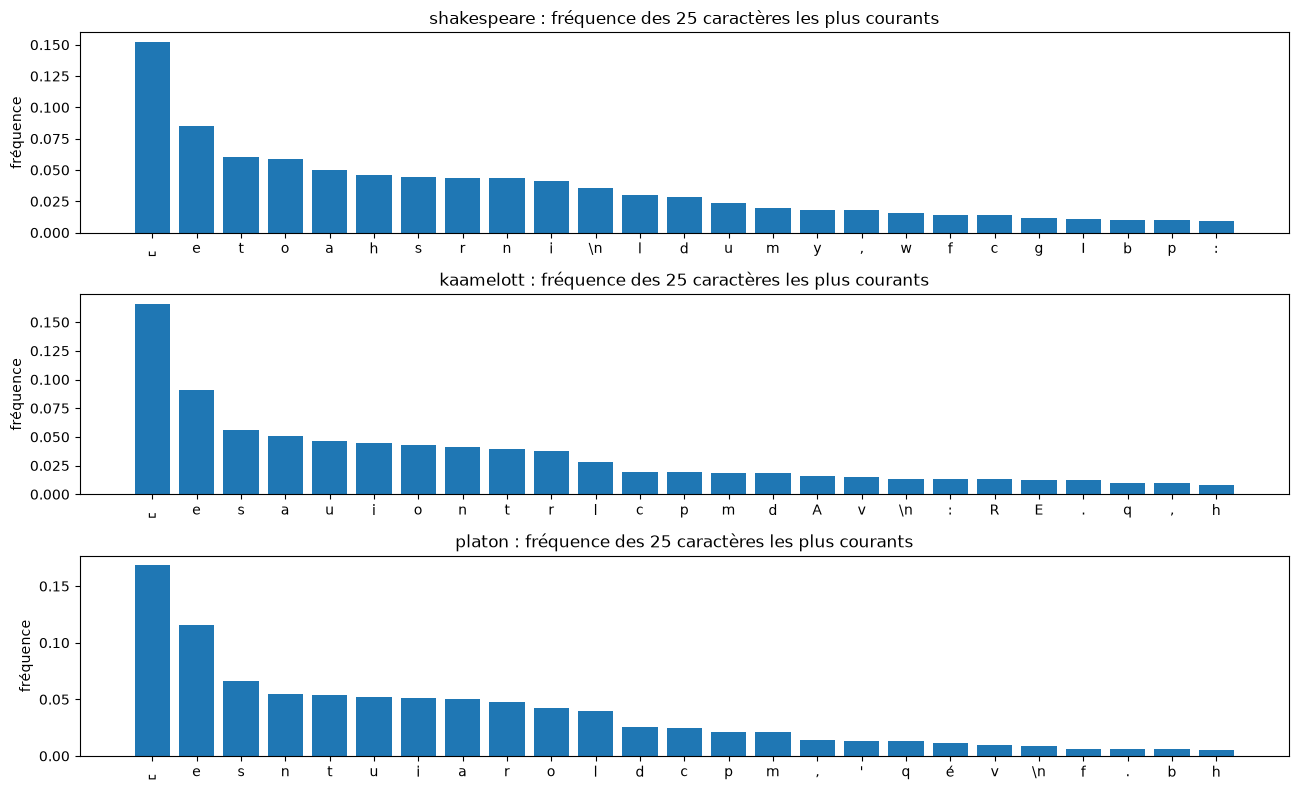

In [5]:
# Quels caractères sont les plus fréquents ? (les 25 premiers)
from collections import Counter

fig, axes = plt.subplots(3, 1, figsize=(13, 8))
for ax, (nom, texte) in zip(axes, textes.items()):
    top = Counter(texte).most_common(25)
    etiquettes = [repr(c)[1:-1] if c not in " \n" else {" ": "␣", "\n": "\\n"}[c] for c, _ in top]
    ax.bar(etiquettes, [n / len(texte) for _, n in top])
    ax.set_title(f"{nom} : fréquence des 25 caractères les plus courants")
    ax.set_ylabel("fréquence")
plt.tight_layout(); plt.show()

L'**espace** domine partout, puis les voyelles. Un modèle qui n'a rien appris d'autre que ces fréquences ferait déjà mieux que le hasard : c'est exactement ce que le bigramme va dépasser, puis le Transformer.

---
## 2. Le tokeniseur : un caractère = un entier

Nous adoptons le **tokeniseur le plus simple possible** :

- `chars` : la liste triée de tous les caractères présents dans le texte, c'est le **vocabulaire** (taille `V`) ;
- `stoi` (*string to integer*) : caractère → indice ;
- `itos` (*integer to string*) : indice → caractère ;
- `encode` / `decode` : appliquer ces tables à une chaîne entière.

Ce code est identique à celui de `minigpt.py` (classe `TokeniseurCaracteres`), que les notebooks suivants importeront.

In [6]:
class TokeniseurCaracteres:
    """Le tokeniseur le plus simple : un caractère = un entier."""

    def __init__(self, texte):
        self.chars = sorted(set(texte))
        self.vocab_size = len(self.chars)
        self.stoi = {ch: i for i, ch in enumerate(self.chars)}
        self.itos = {i: ch for i, ch in enumerate(self.chars)}

    def encode(self, s):
        return [self.stoi[c] for c in s]

    def decode(self, ids):
        return "".join(self.itos[int(i)] for i in ids)


tok = TokeniseurCaracteres(textes["shakespeare"])
print("Vocabulaire :", repr("".join(tok.chars)))
print("V =", tok.vocab_size)
print()
print("encode('Hi there') =", tok.encode("Hi there"))
print("decode(...)        =", repr(tok.decode(tok.encode("Hi there"))))

Vocabulaire : "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
V = 65

encode('Hi there') = [20, 47, 1, 58, 46, 43, 56, 43]
decode(...)        = 'Hi there'


**Un indice est une étiquette, pas une quantité.** Que `e` porte le numéro 43 et `a` le numéro 39 ne veut pas dire que `e` est « plus grand » que `a`, ni qu'ils se ressemblent. C'est pourquoi le modèle n'utilisera jamais l'indice directement dans un calcul : il s'en servira pour **lire une ligne dans une table** (un *embedding*, notebook 02).

### Chaque corpus a son propre vocabulaire

Le tokeniseur est construit **à partir du texte**. Un caractère absent du corpus d'entraînement n'a pas d'indice : le modèle ne pourra ni le lire, ni l'écrire.

In [7]:
tokeniseurs = {nom: TokeniseurCaracteres(t) for nom, t in textes.items()}
for nom, t in tokeniseurs.items():
    print(f"{nom:12s} V = {t.vocab_size:3d} | {''.join(t.chars)[:90]!r}")

phrase = "Arthur, c'est pas faux !"
for nom, t in tokeniseurs.items():
    try:
        t.encode(phrase)
        print(f"{nom:12s} sait encoder {phrase!r}")
    except KeyError as e:
        print(f"{nom:12s} ne connaît pas le caractère {e}")

shakespeare  V =  65 | "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
kaamelott    V = 116 | '\n !"%&\'()+,-./0123456789:;<=>?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]^abcdefghijklmnopqrstuvwxyz{«»ÀÇ'
platon       V = 111 | '\n !"&\'(),-.0123456789:;<=>?ABCDEFGHIJLMNOPQRSTUVWXYZ[\\]^_abcdefghijklmnopqrstuvwxyz|´·ÀÆÇÈ'
shakespeare  sait encoder "Arthur, c'est pas faux !"
kaamelott    sait encoder "Arthur, c'est pas faux !"
platon       sait encoder "Arthur, c'est pas faux !"


Remarquez le piège : Kaamelott contient **deux apostrophes**, la droite `'` et la typographique `’`, selon les épisodes (environ 16 000 et 19 000 occurrences). Pour le modèle, ce sont deux symboles **sans aucun rapport** : il devra apprendre deux fois « c'est », « l'épée », « j'ai »… Un humain y voit le même signe, le tokeniseur non.

> **Pour aller plus loin :** les GPT « industriels » n'utilisent pas des caractères mais des **sous-mots** (BPE : `"Arthur"` → `["Ar", "thur"]`). Le vocabulaire passe à ~50 000 – 200 000 tokens et chaque token porte plus de sens. **Tout le reste du chapitre reste valable** : seul le tokeniseur change. Voir la vidéo de Karpathy [*Let's build the GPT Tokenizer*](https://www.youtube.com/watch?v=zduSFxRajkE).

---
## 3. Tout le corpus devient un tenseur

Une fois `encode` défini, le corpus entier tient dans **un seul long vecteur d'entiers**. Le type `torch.long` est obligatoire : ces entiers serviront d'indices pour `nn.Embedding`.

In [8]:
CORPUS = "shakespeare"     # essayez "kaamelott" ou "platon"
texte = textes[CORPUS]
tok = tokeniseurs[CORPUS]

data = torch.tensor(tok.encode(texte), dtype=torch.long)
print("data :", data.shape, data.dtype)
print("Les 60 premiers indices :", data[:60].tolist())
print("Décodés                 :", repr(tok.decode(data[:60])))

data : torch.Size([1115394]) torch.int64
Les 60 premiers indices : [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56, 43, 1, 61, 43, 1, 54, 56, 53, 41, 43, 43, 42, 1, 39, 52, 63, 1, 44, 59, 56, 58, 46, 43, 56, 6, 1, 46, 43, 39, 56, 1, 51, 43, 1, 57, 54, 43, 39, 49, 8]
Décodés                 : 'First Citizen:\nBefore we proceed any further, hear me speak.'


À ce stade, `data` ne contient **aucune connaissance** : juste des numéros. Les représentations vectorielles apprises apparaîtront avec les embeddings.

---
## 4. Séparer entraînement et validation

Nous gardons les **90 % premiers** caractères pour l'entraînement et les **10 % derniers** pour la validation.

- **Loss d'entraînement** : mesurée sur le texte qui sert à ajuster les poids.
- **Loss de validation** : mesurée sur un texte **jamais utilisé** pour les mises à jour. C'est elle qui dit si le modèle **généralise**.

Si la loss d'entraînement baisse alors que la loss de validation remonte, le modèle **récite** au lieu d'apprendre : c'est le **surapprentissage**.

**Pourquoi couper dans l'ordre plutôt qu'au hasard ?** Si l'on tirait des caractères au hasard, chaque caractère de validation serait entouré de ses voisins… présents dans l'entraînement. La validation deviendrait trop facile. Couper en un seul bloc donne une évaluation honnête sur un passage réellement nouveau.

In [9]:
for nom in textes:
    _, t, train_data, val_data = minigpt.preparer_donnees(nom)
    print(f"{nom:12s} train = {len(train_data):9,} caractères | val = {len(val_data):7,} caractères | V = {t.vocab_size}")

shakespeare  train = 1,003,854 caractères | val = 111,540 caractères | V = 65
kaamelott    train = 2,186,233 caractères | val = 242,915 caractères | V = 116
platon       train = 3,503,608 caractères | val = 389,290 caractères | V = 111


Comme la découpe se fait dans l'ordre, la validation de Kaamelott correspond aux **derniers épisodes** de la série, et celle de Platon aux derniers dialogues du fichier : le modèle sera évalué sur des scènes qu'il n'a jamais vues.

---
## 5. Un premier repère : le modèle « je ne sais rien »

Un modèle qui donne la même probabilité `1/V` à chaque caractère obtient une loss (negative log-likelihood, chapitre 1) de

$$\mathcal{L}_{\text{uniforme}} = -\log\frac{1}{V} = \log V.$$

C'est la **ligne de départ** : tout modèle qui a appris quelque chose doit faire mieux.

In [10]:
for nom, t in tokeniseurs.items():
    print(f"{nom:12s} V = {t.vocab_size:3d}  ->  loss uniforme = log(V) = {math.log(t.vocab_size):.3f}")

shakespeare  V =  65  ->  loss uniforme = log(V) = 4.174
kaamelott    V = 116  ->  loss uniforme = log(V) = 4.754
platon       V = 111  ->  loss uniforme = log(V) = 4.710


## À retenir

- Un corpus = une longue chaîne de caractères, **espaces et retours à la ligne compris**.
- Le **vocabulaire** est l'ensemble des caractères distincts ; `stoi`/`itos` font l'aller-retour caractère ↔ entier.
- Le corpus devient un tenseur `torch.long` ; on le coupe **dans l'ordre** en train (90 %) / val (10 %).
- La loss de référence d'un modèle qui ne sait rien est `log(V)`.
- Ces fonctions sont rangées dans `minigpt.py` : `charger_texte`, `TokeniseurCaracteres`, `preparer_donnees`.

**Questions de vérification**
1. Pourquoi ne peut-on pas générer le caractère `é` avec un modèle entraîné sur Shakespeare ?
2. Pourquoi l'indice d'un caractère ne doit-il pas être utilisé comme une grandeur numérique ?
3. Pourquoi les deux apostrophes de Kaamelott (`'` et `’`) sont-elles un problème pour un tokeniseur caractère ?

**Suite → 02 :** nous reprenons le bigramme du chapitre 1, cette fois écrit « à la PyTorch » avec `nn.Module`, et nous l'entraînons sur ce texte.

### Références
- A. Karpathy, [*char-rnn*](https://github.com/karpathy/char-rnn) — origine du corpus *Tiny Shakespeare*.
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) et son code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture).
- A. Karpathy, [*Let's build the GPT Tokenizer*](https://www.youtube.com/watch?v=zduSFxRajkE) (2024) — tokenisation en sous-mots (BPE).
- Platon, *Œuvres*, trad. Victor Cousin, sur [Wikisource](https://fr.wikisource.org/wiki/Auteur:Platon).